# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display_html
from io import StringIO
import seaborn as sns



In [2]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [3]:
# explorar datasets
orders.head(5)

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [4]:
catalog.head(5)

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [5]:
marketing.head(5)

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


##### 📝 Primera inspección de los datos

La visualización de las primeras filas permite conocer la estructura y el tipo de información disponible en cada dataset.

- **`orders`** contiene la información de los pedidos realizados, incluyendo datos del cliente, producto, cantidad, precio, descuentos y monto total.
- **`catalog`** contiene la información de los productos, como su nombre, categoría, costo unitario y proveedor, por lo que puede relacionarse con `orders` mediante `nombre_producto`.
- **`marketing`** contiene información sobre las campañas de marketing, incluyendo fecha, país, canal, identificador de campaña y gasto.

Esta primera inspección permite comprender cómo se organiza la información y anticipar las relaciones que podrán establecerse entre los datasets durante el análisis.

---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas 

---

In [6]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [7]:
catalog.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


In [8]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


##### 📝 Observaciones iniciales

A partir de la revisión general de los datasets se identificó lo siguiente:

- **`orders`**
  - Contiene **25,100 registros y 12 columnas**.
  - Se identificaron valores ausentes en:
    - `pais`
    - `dispositivo`
    - `fuente_referencia`
    - `nombre_producto`
    - `categoria_producto`
    - `cantidad`
    - `precio_unitario`
    - `monto_descuento`
  - La columna `fecha_hora_pedido` está almacenada como `object`, por lo que será necesario convertirla a formato de fecha.

- **`catalog`**
  - Contiene **7 registros y 4 columnas**.
  - No presenta valores ausentes.
  - Los tipos de datos observados son coherentes con la información almacenada.

- **`marketing`**
  - Contiene **1,620 registros y 5 columnas**.
  - Se identificaron valores ausentes en:
    - `canal`
  - La columna `fecha` está almacenada como `object`, por lo que será necesario convertirla a formato de fecha.


---

### 🔎 Revisión de valores ausentes

Después de identificar valores ausentes en los datasets `orders` y `marketing`, se realiza una revisión para determinar si es posible recuperar la información utilizando otros datos disponibles, cuando no sea posible recuperar los valores faltantes, se evaluará su importancia para los análisis posteriores antes de decidir si se conservan, se reemplazan o se eliminan los registros afectados.

In [9]:
# Calcular valores ausentes en orders
nulos_orders = pd.DataFrame({
    'cantidad': orders.isna().sum(),
    'porcentaje': (orders.isna().mean() * 100).round(2)
})

# Conservar únicamente las columnas que tienen valores ausentes
nulos_orders = nulos_orders[nulos_orders['cantidad'] > 0]

print(nulos_orders)


                    cantidad  porcentaje
pais                     300        1.20
dispositivo               20        0.08
fuente_referencia         30        0.12
nombre_producto           30        0.12
categoria_producto        80        0.32
cantidad                  50        0.20
precio_unitario           50        0.20
monto_descuento           50        0.20


In [10]:
# Calcular valores ausentes en marketing
nulos_marketing = pd.DataFrame({
    'cantidad': marketing.isna().sum(),
    'porcentaje': (marketing.isna().mean() * 100).round(2)
})

# Conservar únicamente las columnas que tienen valores ausentes
nulos_marketing = nulos_marketing[nulos_marketing['cantidad'] > 0]

print(nulos_marketing)


       cantidad  porcentaje
canal       101        6.23


##### 📝 Inspección de valores ausentes

Se calculó la **cantidad y el porcentaje de valores ausentes por variable** para conocer qué proporción de la información está incompleta y evaluar posteriormente el tratamiento más adecuado.

Los resultados obtenidos fueron:

- **`orders`**
    - `pais`: 300 valores ausentes (**1.20 %**).
    - `dispositivo`: 20 valores ausentes (**0.08 %**).
    - `fuente_referencia`: 30 valores ausentes (**0.12 %**).
    - `nombre_producto`: 30 valores ausentes (**0.12 %**).
    - `categoria_producto`: 80 valores ausentes (**0.32 %**).
    - `cantidad`: 50 valores ausentes (**0.20 %**).
    - `precio_unitario`: 50 valores ausentes (**0.20 %**).
    - `monto_descuento`: 50 valores ausentes (**0.20 %**).

- **`marketing`**
    - `canal`: 101 valores ausentes (**6.23 %**).

Aunque la mayoría de los porcentajes son pequeños, no se eliminarán los registros de forma inmediata. Primero se revisará si la información faltante puede recuperarse a partir de otras variables o mediante la relación entre los datasets.

---

In [11]:
# Revisar patrones de valores ausentes en orders
columnas_nulas = [
    'pais',
    'dispositivo',
    'fuente_referencia',
    'nombre_producto',
    'categoria_producto',
    'cantidad',
    'precio_unitario',
    'monto_descuento'
]

orders[columnas_nulas].isna().value_counts()

pais   dispositivo  fuente_referencia  nombre_producto  categoria_producto  cantidad  precio_unitario  monto_descuento
False  False        False              False            False               False     False            False              24700
True   False        False              False            False               False     False            False                300
False  False        False              False            True                True      True             True                  50
                    True               True             True                False     False            False                 30
       True         False              False            False               False     False            False                 20
dtype: int64

##### 📝 Patrones de valores ausentes en `orders`

Para comprender cómo se distribuyen los valores ausentes, se analizaron conjuntamente las columnas que presentan datos faltantes en el DataFrame `orders`. En la tabla que se muestra **`True` indica que el valor está ausente y `False` que está presente**.

Se identificaron cinco patrones:

- **24,700 registros** no presentan valores ausentes en ninguna de las columnas analizadas.

- **300 registros** presentan un valor ausente únicamente en:
  - `pais`

- **50 registros** presentan valores ausentes simultáneamente en:
  - `categoria_producto`
  - `cantidad`
  - `precio_unitario`
  - `monto_descuento`

- **30 registros** presentan valores ausentes simultáneamente en:
  - `fuente_referencia`
  - `nombre_producto`
  - `categoria_producto`

- **20 registros** presentan un valor ausente únicamente en:
  - `dispositivo`

Los resultados muestran que los valores ausentes **no se encuentran distribuidos de manera independiente**, sino que algunos se concentran en grupos específicos de registros. Por esta razón, cada patrón debe analizarse antes de decidir si los valores pueden recuperarse, imputarse o si es necesario eliminar los registros afectados.

In [12]:
# Visualizar ejemplos de cada patrón de valores ausentes

print("Solo falta pais:")
display(orders[orders['pais'].isna()].head(3))

print("Solo falta dispositivo:")
display(orders[orders['dispositivo'].isna()].head(3))

print("Faltan fuente_referencia, nombre_producto y categoria_producto:")
display(
    orders[
        orders['fuente_referencia'].isna() &
        orders['nombre_producto'].isna() &
        orders['categoria_producto'].isna()
    ].head(3)
)

print("Faltan categoria_producto, cantidad, precio_unitario y monto_descuento:")
display(
    orders[
        orders['categoria_producto'].isna() &
        orders['cantidad'].isna() &
        orders['precio_unitario'].isna() &
        orders['monto_descuento'].isna()
    ].head(3)
)

Solo falta pais:


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
124,order_124,user_6671,2025-04-12,NaN,mobile,organic,Blender-XL-Red,Hogar,1.0,298.44,5.0,293.44
125,order_125,user_5263,2025-05-30,NaN,mobile,organic,Tablet-Standard-64GB,Electronica,1.0,133.13,0.0,133.13
126,order_126,user_4952,2025-04-19,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,2.0,177.23,0.0,354.45


Solo falta dispositivo:


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
24,order_24,user_458,2025-01-05,Colombia,NaN,organic,Sneakers-Urban-42,Moda,2.0,117.99,0.0,235.99
25,order_25,user_540,2025-03-08,Argentina,NaN,social,Vacuum-Pro-Black,Hogar,1.0,183.50,5.0,178.50
26,order_26,user_1951,2025-02-10,Colombia,NaN,organic,Blender-XL-Red,Hogar,1.0,331.52,15.0,316.52


Faltan fuente_referencia, nombre_producto y categoria_producto:


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
44,order_44,user_2899,2025-02-22,Colombia,desktop,NaN,NaN,NaN,1.0,318.38,5.0,313.38
45,order_45,user_6196,2025-02-10,Mexico,mobile,NaN,NaN,NaN,2.0,354.06,10.0,698.12
46,order_46,user_5815,2025-04-24,Mexico,mobile,NaN,NaN,NaN,1.0,359.31,10.0,349.31


Faltan categoria_producto, cantidad, precio_unitario y monto_descuento:


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
74,order_74,user_6172,2025-01-15,Argentina,desktop,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,595.85
75,order_75,user_6588,2025-06-19,Colombia,mobile,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,458.15
76,order_76,user_3193,2025-03-17,Argentina,mobile,paid_search,Laptop-Gaming-16GB,NaN,NaN,NaN,NaN,319.75


---

##### Tratamiento de valores ausentes en `pais`

Se identificaron 300 registros en los que falta únicamente el país. Se revisó la información disponible, pero no se encontró otra variable que permita determinar el país de manera confiable. Debido a que `pais` no es necesario para calcular los indicadores generales de ingresos, costos y rentabilidad, no se justifica eliminar estos pedidos, ya que contienen información válida para dichos análisis. Por lo tanto, los registros se conservarán y los valores ausentes de `pais` se reemplazarán por `Desconocido`. Esta categoría permitirá identificarlos en caso de realizar posteriormente un análisis por país.

In [13]:
# Reemplazar valores ausentes de pais
orders['pais'] = orders['pais'].fillna('Desconocido')
# Verificar
print("Valores ausentes en pais:", orders['pais'].isna().sum())

Valores ausentes en pais: 0


---

##### Tratamiento de valores ausentes en `dispositivo`

Se identificaron 20 registros sin información sobre el dispositivo utilizado. Al revisar las demás variables, no se encontró información que permita determinar de manera confiable si el pedido se realizó desde `mobile` o `desktop`. Debido a que `dispositivo` no es necesario para calcular los indicadores generales de ingresos, costos y rentabilidad, se conservarán estos pedidos y los valores ausentes se reemplazarán por `Desconocido`. Esta categoría permitirá mantener los registros e identificarlos en caso de realizar posteriormente un análisis por dispositivo.

In [14]:
# Reemplazar valores ausentes de dispositivo
orders['dispositivo'] = orders['dispositivo'].fillna('Desconocido')

# Verificar
print("Valores ausentes en dispositivo:", orders['dispositivo'].isna().sum())

Valores ausentes en dispositivo: 0


---

##### Registros con `fuente_referencia`, `nombre_producto` y `categoria_producto` ausentes
Se identificaron 30 registros en los que faltan simultáneamente `fuente_referencia`, `nombre_producto` y `categoria_producto`. Se revisan estos registros para determinar si la información faltante puede recuperarse antes de decidir su tratamiento.

In [15]:
# Revisar registros sin producto identificado
orders[
    orders['nombre_producto'].isna()
][
    [
        'id_pedido',
        'fuente_referencia',
        'nombre_producto',
        'categoria_producto',
        'cantidad',
        'precio_unitario',
        'monto_descuento',
        'monto_total'
    ]
].head(5)

,id_pedido,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
44,order_44,NaN,NaN,NaN,1.0,318.38,5.0,313.38
45,order_45,NaN,NaN,NaN,2.0,354.06,10.0,698.12
46,order_46,NaN,NaN,NaN,1.0,359.31,10.0,349.31
47,order_47,NaN,NaN,NaN,2.0,476.78,0.0,953.56
48,order_48,NaN,NaN,NaN,2.0,137.96,0.0,275.93


###### 📝 Decisión

No se encontró información suficiente para identificar de manera confiable el producto vendido. Sin `nombre_producto`, estos pedidos no pueden relacionarse con `catalog` para obtener su `costo_unitario`, necesario para calcular los costos y la rentabilidad. Por esta razón, se eliminarán los 30 registros.

In [16]:
# Eliminar registros sin producto identificado
orders = orders.dropna(subset=['nombre_producto']).copy()

# Verificar
print("Registros restantes:", len(orders))
print("Valores ausentes en nombre_producto:", orders['nombre_producto'].isna().sum())

Registros restantes: 25070
Valores ausentes en nombre_producto: 0


---

##### 🔎 Registros con cuatro valores ausentes

Se identificaron 50 registros en los que faltan simultáneamente `categoria_producto`, `cantidad`, `precio_unitario` y `monto_descuento`. A diferencia del caso anterior, estos pedidos conservan información como `nombre_producto` y `monto_total`. Por ello, se revisarán los registros para determinar si los valores faltantes pueden recuperarse antes de decidir su tratamiento.

In [17]:
# Visualizar información relevante
orders.loc[
    orders[['categoria_producto', 'cantidad', 
            'precio_unitario', 'monto_descuento']].isna().all(axis=1),
    ['id_pedido', 'nombre_producto', 'categoria_producto',
     'cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']
].head(5)

,id_pedido,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
74,order_74,Sneakers-Urban-42,NaN,NaN,NaN,NaN,595.85
75,order_75,Sneakers-Urban-42,NaN,NaN,NaN,NaN,458.15
76,order_76,Laptop-Gaming-16GB,NaN,NaN,NaN,NaN,319.75
77,order_77,Vacuum-Pro-Black,NaN,NaN,NaN,NaN,227.55
78,order_78,Phone-Pro-128GB,NaN,NaN,NaN,NaN,432.39


Los registros conservan `nombre_producto` y `monto_total`, por lo que es posible identificar el producto vendido y el ingreso generado por cada pedido. Sin embargo, para calcular el costo de los productos vendidos se necesita conocer la `cantidad`, ya que posteriormente el costo de cada pedido se obtendrá utilizando la cantidad vendida y el `costo_unitario` disponible en `catalog`. Como también falta `precio_unitario`, se revisarán los precios registrados de cada producto para determinar si existe un precio único que permita recuperar esta información y, a partir de ella, evaluar si es posible reconstruir la `cantidad`.

In [18]:
# Revisar los precios registrados para cada producto
orders.groupby('nombre_producto')['precio_unitario'].agg(
    ['count', 'nunique', 'min', 'max']
)

,count,nunique,min,max
nombre_producto,,,,
Blender-XL-Red,4192,4012,20.06,499.94
Jacket-Winter-M,4182,3993,20.06,499.93
Laptop-Gaming-16GB,2790,2705,20.24,499.95
Phone-Pro-128GB,2747,2659,20.08,499.86
Sneakers-Urban-42,4141,3949,20.11,499.91
Tablet-Standard-64GB,2775,2696,20.03,499.89
Vacuum-Pro-Black,4193,4017,20.37,499.96


Los resultados muestran que un mismo producto presenta una gran cantidad de precios diferentes y un rango amplio de valores. Por esta razón, utilizar una media o mediana no permitiría recuperar el precio de cada pedido de manera confiable y, en consecuencia, tampoco sería posible utilizarlo junto con `monto_total` para obtener la `cantidad`.

Como alternativa, se analizará la información disponible en `catalog`. Debido a que `nombre_producto` está disponible, es posible relacionar cada pedido con su `costo_unitario`. Primero se revisará la variación de estos costos entre productos para determinar si esta información puede ser útil para el tratamiento de los registros.


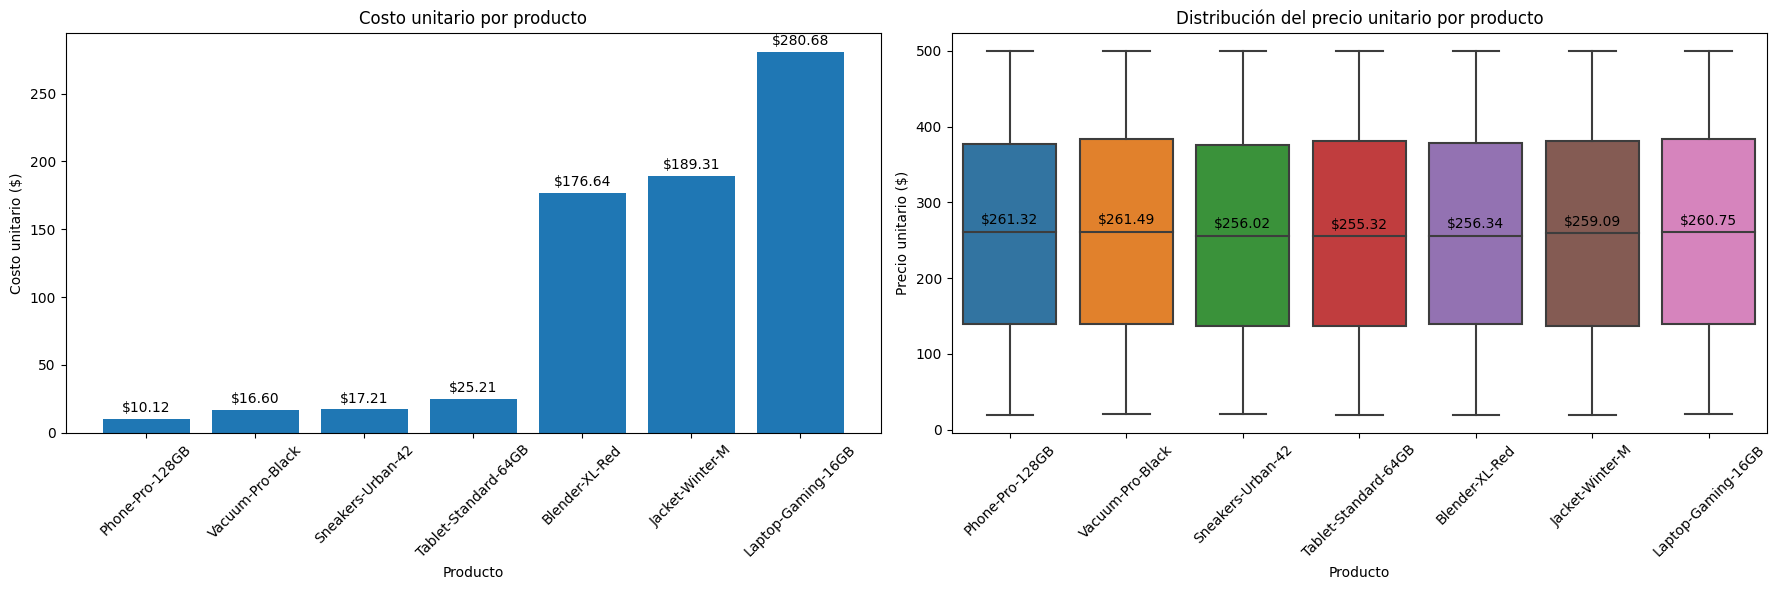

In [19]:

# Ordenar productos por costo unitario
catalog_ordenado = catalog.sort_values('costo_unitario')
orden_productos = catalog_ordenado['nombre_producto'].tolist()

# Crear una figura con dos gráficas en el mismo renglón
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# -------------------------------------------------
# Gráfica 1: costo unitario por producto
# -------------------------------------------------

barras = axes[0].bar(
    catalog_ordenado['nombre_producto'],
    catalog_ordenado['costo_unitario']
)

# Agregar valor encima de cada barra
for barra in barras:
    altura = barra.get_height()

    axes[0].text(
        barra.get_x() + barra.get_width() / 2,
        altura + 5,
        f'${altura:.2f}',
        ha='center'
    )

axes[0].set_title('Costo unitario por producto')
axes[0].set_xlabel('Producto')
axes[0].set_ylabel('Costo unitario ($)')
axes[0].tick_params(axis='x', rotation=45)


# -------------------------------------------------
# Gráfica 2: distribución del precio unitario
# -------------------------------------------------

sns.boxplot(
    data=orders,
    x='nombre_producto',
    y='precio_unitario',
    order=orden_productos,
    ax=axes[1]
)

# Calcular mediana de precio por producto
medianas = (
    orders.groupby('nombre_producto')['precio_unitario']
    .median()
)

# Mostrar valor de la mediana
for i, producto in enumerate(orden_productos):
    mediana = medianas[producto]

    axes[1].text(
        i,
        mediana + 10,
        f'${mediana:.2f}',
        ha='center'
    )

axes[1].set_title('Distribución del precio unitario por producto')
axes[1].set_xlabel('Producto')
axes[1].set_ylabel('Precio unitario ($)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

La comparación muestra que los productos presentan costos unitarios muy diferentes en `catalog`, con valores entre $10.12$ y $280.68$. Sin embargo, estas diferencias no se reflejan en los precios de venta registrados en `orders`.

Las distribuciones de `precio_unitario` son muy similares entre los productos y sus medianas se encuentran aproximadamente entre $255$ y $261$, por lo que no se observa un patrón que permita relacionar el precio de venta con el costo del producto.

Por esta razón, no es posible recuperar de manera confiable el `precio_unitario`. Además, al faltar simultáneamente `cantidad` y `monto_descuento`, tampoco es posible reconstruir estas variables a partir del `monto_total` sin introducir estimaciones arbitrarias.

Por lo tanto, se eliminarán estos 50 registros para evitar introducir información estimada que pueda afectar posteriormente el cálculo de costos y rentabilidad.

In [20]:
# Eliminar registros sin cantidad, precio unitario y monto de descuento
orders = orders.dropna(
    subset=['cantidad', 'precio_unitario', 'monto_descuento']
).copy()

# Verificar
print("Registros restantes:", len(orders))
print("\nValores ausentes:")
print(
    orders[
        ['cantidad', 'precio_unitario', 'monto_descuento']
    ].isna().sum()
)

Registros restantes: 25020

Valores ausentes:
cantidad           0
precio_unitario    0
monto_descuento    0
dtype: int64


---

In [21]:
# Verificar valores ausentes restantes en orders
orders.isna().sum()

id_pedido             0
id_usuario            0
fecha_hora_pedido     0
pais                  0
dispositivo           0
fuente_referencia     0
nombre_producto       0
categoria_producto    0
cantidad              0
precio_unitario       0
monto_descuento       0
monto_total           0
dtype: int64

##### 📝 Resumen del tratamiento de valores ausentes en `orders`

- Los **30 registros sin `nombre_producto`** fueron eliminados, ya que no era posible identificar el producto vendido ni relacionarlo con `catalog` para obtener su costo.
- Los **50 registros con información transaccional insuficiente** fueron eliminados después de comprobar que `cantidad`, `precio_unitario` y `monto_descuento` no podían recuperarse de manera confiable con la información disponible.
- Los valores ausentes en variables categóricas que no podían recuperarse de forma confiable fueron sustituidos por `Desconocido`, evitando asignar categorías existentes sin evidencia.
- La verificación final mediante `isna().sum()` confirma que **no quedan valores ausentes en `orders`**.

De esta manera, se completa el tratamiento de valores ausentes en `orders`.

---

##### 🔎 Valores ausentes en `Marketing`

Durante la exploración inicial se identificaron valores ausentes en `Marketing`. A continuación, se analizarán estos registros para determinar qué información falta, si existe algún patrón entre los valores ausentes y si es posible recuperar la información de manera confiable antes de decidir su tratamiento.

In [22]:
# Visualizar registros con valores ausentes en marketing
marketing[marketing.isna().any(axis=1)].head(5)

,fecha,pais,id_campaña,canal,gasto
98,2025-01-11,Argentina,social_Argentina,NaN,849.70
99,2025-01-12,Mexico,organic_Mexico,NaN,2033.56
100,2025-01-12,Mexico,paid_search_Mexico,NaN,1260.65
101,2025-01-12,Mexico,social_Mexico,NaN,1660.90
102,2025-01-12,Colombia,organic_Colombia,NaN,1819.27


In [23]:
# Revisar la relación entre id_campaña y canal
marketing.groupby('id_campaña')['canal'].unique()

id_campaña
organic_Argentina            [organic, nan]
organic_Colombia             [organic, nan]
organic_Mexico               [organic, nan]
paid_search_Argentina    [paid_search, nan]
paid_search_Colombia     [paid_search, nan]
paid_search_Mexico       [paid_search, nan]
social_Argentina              [social, nan]
social_Colombia               [social, nan]
social_Mexico                 [social, nan]
Name: canal, dtype: object

##### 📝 Análisis de los valores ausentes en `canal`

Se analizó la relación entre `id_campaña` y `canal` para determinar si los 101 valores ausentes podían recuperarse a partir de información existente. Los resultados muestran una correspondencia consistente entre cada campaña y su canal. Para cada `id_campaña`, los registros disponibles presentan un único canal conocido, mientras que algunos registros contienen valores ausentes. Por lo tanto, los valores faltantes de `canal` pueden recuperarse utilizando el canal observado en otros registros pertenecientes a la misma `id_campaña`.

In [24]:
# Recuperar canal a partir de otros registros de la misma campaña
marketing['canal'] = (
    marketing.groupby('id_campaña')['canal']
    .transform(lambda x: x.fillna(x.dropna().iloc[0]))
)

In [25]:
# Verificar valores ausentes en marketing
marketing.isna().sum()

fecha         0
pais          0
id_campaña    0
canal         0
gasto         0
dtype: int64

##### 📝 Resumen de valores ausentes en `marketing`

Los **101 valores ausentes** de `canal` fueron recuperados utilizando la información disponible en `id_campaña`. Se comprobó previamente que cada campaña mantiene una correspondencia consistente con un único canal conocido, por lo que fue posible completar los valores faltantes sin introducir información arbitraria.

La validación final mediante `isna().sum()` confirma que **no quedan valores ausentes en `marketing`**.

---

---

### 🔢 Revisión de variables numéricas

Una vez tratados los valores ausentes, se revisan las variables numéricas de los tres datasets con el objetivo de detectar valores que puedan afectar los análisis posteriores.

Se evaluarán:

- valores negativos en variables donde no deberían existir;
- ceros potencialmente inválidos;
- valores extremadamente altos o atípicos;
- rangos y distribución general de las variables.

Posteriormente, cada problema identificado será analizado antes de decidir su tratamiento.

In [26]:
# Revisar variables numéricas
print(orders.describe())
print(catalog.describe())
print(marketing.describe())

           cantidad  precio_unitario  monto_descuento   monto_total
count  25020.000000     25020.000000     25020.000000  2.502000e+04
mean       7.099440       259.299232         4.501199  2.077952e+03
std      296.454517       138.718086         5.222860  9.910798e+04
min       -2.000000        20.030000         0.000000 -4.926500e+02
25%        1.000000       138.435000         0.000000  1.803275e+02
50%        2.000000       258.700000         0.000000  3.414800e+02
75%        2.000000       380.297500        10.000000  5.181525e+02
max    20000.000000       499.960000        15.000000  8.840200e+06
       costo_unitario
count        7.000000
mean       102.252857
std        111.011563
min         10.120000
25%         16.905000
50%         25.210000
75%        182.975000
max        280.680000
            gasto
count  1620.00000
mean   1772.74292
std     734.43294
min     501.11000
25%    1128.03000
50%    1782.42500
75%    2420.68500
max    2999.36000


##### 📝 Revisión estadística de variables numéricas

El resumen estadístico permite identificar los siguientes aspectos:

- **`cantidad`:**
  - La mayoría de los pedidos presenta cantidades de **1 o 2 unidades**, como muestran los cuartiles.
  - Sin embargo, se observa un mínimo de **-2** y un máximo de **20,000**, valores que no son coherentes con el comportamiento general de la variable.
  - Estos resultados confirman la presencia de valores anómalos que requieren una revisión específica.

- **`precio_unitario`:**
  - Los valores se encuentran entre **20.03 y 499.96**.
  - No se observan valores negativos ni iguales a cero.

- **`monto_descuento`:**
  - Los valores se encuentran entre **0 y 15**.
  - El valor cero es válido, ya que puede representar pedidos sin descuento.

- **`monto_total`:**
  - Se observa un mínimo de aproximadamente **-492.65** y un máximo de **8,840,200**.
  - La presencia de montos negativos y extremadamente altos requiere revisión, ya que podría estar relacionada con las anomalías detectadas en `cantidad`.

- **`costo_unitario`:**
  - Presenta valores entre **10.12 y 280.68**, sin valores negativos ni iguales a cero.

- **`gasto`:**
  - Presenta valores entre **501.11 y 2,999.36**, sin valores negativos ni iguales a cero.

En consecuencia, los principales problemas numéricos se concentran en `cantidad` y `monto_total`. Antes de realizar correcciones, se revisarán los registros afectados para determinar la relación entre estas anomalías y evitar modificar datos válidos.

##### 🔎 Revisión de valores anómalos en `cantidad`

In [27]:
# Revisar valores y frecuencia de cantidad
orders['cantidad'].value_counts().sort_index()

-2.0            1
-1.0            3
 1.0        12379
 2.0        12627
 10000.0        6
 20000.0        4
Name: cantidad, dtype: int64

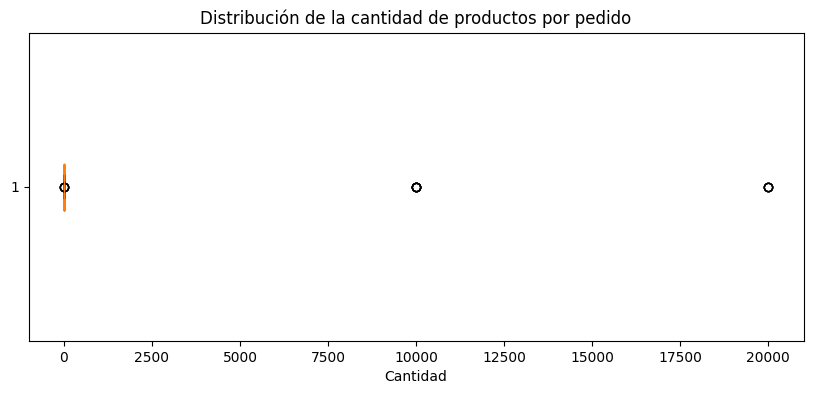

In [28]:
# Visualizar posibles valores atípicos en cantidad
plt.figure(figsize=(10, 4))

plt.boxplot(orders['cantidad'].dropna(), vert=False)

plt.title('Distribución de la cantidad de productos por pedido')
plt.xlabel('Cantidad')

plt.show()

La revisión confirma que la distribución de `cantidad` se concentra casi por completo en pedidos de **1 o 2 unidades**. Sin embargo, se identificaron **4 registros con cantidades negativas** y **10 registros con cantidades extremadamente altas de 10,000 o 20,000 unidades**. Estos valores presentan un comportamiento claramente diferente al resto de los pedidos y requieren una revisión individual antes de decidir su tratamiento. Debido a que `cantidad` interviene directamente en el cálculo del valor de la transacción, a continuación se revisarán estos registros junto con `precio_unitario`, `monto_descuento` y `monto_total` para determinar cómo afectan los montos registrados.

In [29]:
# Revisar registros con cantidades anómalas
orders[
    ~orders['cantidad'].isin([1, 2])
][[
    'id_pedido',
    'nombre_producto',
    'cantidad',
    'precio_unitario',
    'monto_descuento',
    'monto_total'
]]

,id_pedido,nombre_producto,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,Phone-Pro-128GB,-2.0,101.31,10.0,-192.62
267,order_267,Phone-Pro-128GB,-1.0,43.50,5.0,-38.50
268,order_268,Phone-Pro-128GB,-1.0,497.65,5.0,-492.65
269,order_269,Phone-Pro-128GB,-1.0,423.53,0.0,-423.53
3521,order_3521,Laptop-Gaming-16GB,10000.0,43.14,0.0,431400.00
3522,order_3522,Laptop-Gaming-16GB,10000.0,280.55,0.0,2805500.00
3586,order_3586,Laptop-Gaming-16GB,10000.0,490.35,0.0,4903500.00
3643,order_3643,Laptop-Gaming-16GB,10000.0,238.15,0.0,2381500.00
3656,order_3656,Laptop-Gaming-16GB,20000.0,297.66,0.0,5953200.00
3668,order_3668,Laptop-Gaming-16GB,20000.0,348.31,0.0,6966200.00


La revisión de los registros confirma que los valores extremos de `monto_total` están asociados con valores anómalos de `cantidad`. Los pedidos con cantidades de **10,000 y 20,000 unidades** generan montos totales considerablemente superiores al comportamiento habitual del dataset. Asimismo, los registros con cantidades negativas presentan montos totales negativos. Dado que la distribución general de `cantidad` se concentra en pedidos de **1 o 2 unidades**, estos 14 registros presentan un comportamiento claramente anómalo.

In [30]:
# Calcular cuartiles e IQR de cantidad
Q1 = orders['cantidad'].quantile(0.25)
Q3 = orders['cantidad'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Q1: 1.0
Q3: 2.0
IQR: 1.0
Límite inferior: -0.5
Límite superior: 3.5


El análisis mediante el rango intercuartílico (IQR) mostró que el 50 % central de los valores de `cantidad` se encuentra entre 1 y 2 unidades.

A partir de estos cuartiles se obtuvieron los siguientes límites:

- Límite inferior: **-0.5**
- Límite superior: **3.5**

Por lo tanto, los valores de `cantidad` inferiores a -0.5 o superiores a 3.5 serán considerados posibles valores atípicos.

Es importante señalar que este criterio permite detectar observaciones inusuales, pero no determina por sí mismo que sean errores.

In [31]:
# Identificar posibles valores atípicos mediante IQR
cantidad_anomala = (
    (orders['cantidad'] < limite_inferior) |
    (orders['cantidad'] > limite_superior)
)

print(
    "Registros fuera de los límites del IQR:",
    cantidad_anomala.sum()
)

Registros fuera de los límites del IQR: 14


Mediante el criterio del rango intercuartílico (IQR) se identificaron **14 registros fuera de los límites establecidos para `cantidad`**.

La distribución de estos valores es:

- `-2`: 1 registro.
- `-1`: 3 registros.
- `10000`: 6 registros.
- `20000`: 4 registros.

Los valores negativos no representan cantidades válidas de productos comprados. Asimismo, las cantidades de 10,000 y 20,000 unidades se encuentran considerablemente alejadas de la distribución habitual de los pedidos.

In [32]:
# Calcular el monto esperado
orders['monto_calculado'] = (
    orders['cantidad'] * orders['precio_unitario']
    - orders['monto_descuento']
)

# Calcular la diferencia
orders['diferencia_monto'] = (
    orders['monto_total'] - orders['monto_calculado']
).abs()

# Identificar registros con diferencias mayores a 0.02
monto_inconsistente = orders['diferencia_monto'] > 0.02

print("Registros con montos inconsistentes:", monto_inconsistente.sum())

Registros con montos inconsistentes: 3


In [33]:
# Revisar registros con montos inconsistentes
orders.loc[
    monto_inconsistente,
    [
        'id_pedido',
        'cantidad',
        'precio_unitario',
        'monto_descuento',
        'monto_total',
        'monto_calculado',
        'diferencia_monto'
    ]
]

,id_pedido,cantidad,precio_unitario,monto_descuento,monto_total,monto_calculado,diferencia_monto
266,order_266,-2.0,101.31,10.0,-192.62,-212.62,20.0
267,order_267,-1.0,43.50,5.0,-38.50,-48.50,10.0
268,order_268,-1.0,497.65,5.0,-492.65,-502.65,10.0


Se identificaron **3 registros** en los que el `monto_total` registrado no coincide con el monto calculado mediante:

`cantidad × precio_unitario - monto_descuento`

Las diferencias encontradas son de **10.00 a 20.00**, por lo que no corresponden únicamente a pequeñas variaciones de redondeo.

Además, los tres registros presentan valores negativos en `cantidad`, problema identificado previamente durante la revisión de valores anómalos. Esto indica que estas observaciones presentan más de una inconsistencia y no pueden corregirse de manera confiable sin conocer los valores originales.

##### 📝 Tratamiento de cantidades anómalas

Debido a que no existe información suficiente para determinar los valores originales de `cantidad`, se decidió no sustituir las cantidades anómalas por valores estimados.

Los **14 registros afectados** representan aproximadamente el **0.06 %** de los pedidos actuales. Por esta razón, se eliminarán estos registros para evitar que cantidades inválidas y los montos asociados distorsionen los análisis posteriores de ingresos y rentabilidad.

In [34]:
# Eliminar registros con cantidades anómalas
orders = orders[~cantidad_anomala].copy()

print("Registros eliminados:", cantidad_anomala.sum())
print("Registros restantes:", len(orders))

Registros eliminados: 14
Registros restantes: 25006


In [35]:
# Validar variables numéricas después de la limpieza
orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']].describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,25006.000000,25006.000000,25006.000000,25006.000000
mean,1.504959,259.287577,4.502919,385.779982
std,0.499985,138.708547,5.223351,255.708123
min,1.000000,20.030000,0.000000,5.240000
25%,1.000000,138.440000,0.000000,180.330000
50%,2.000000,258.680000,0.000000,341.360000
75%,2.000000,380.272500,10.000000,517.622500
max,2.000000,499.960000,15.000000,999.890000


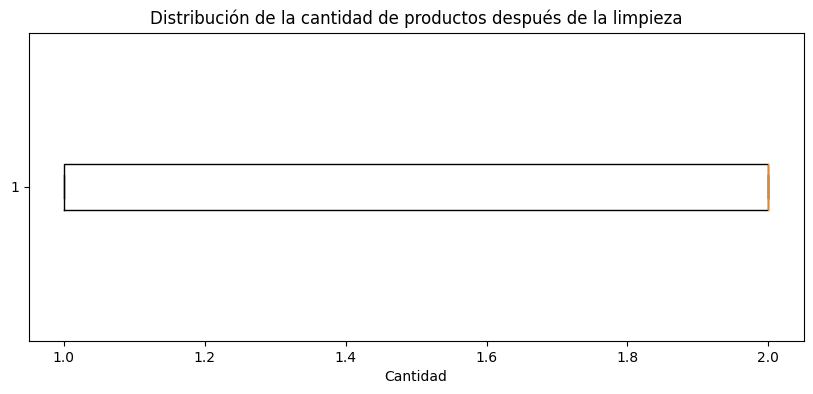

In [36]:
# Visualizar la distribución de cantidad después de la limpieza
plt.figure(figsize=(10, 4))

plt.boxplot(orders['cantidad'], vert=False)

plt.title('Distribución de la cantidad de productos después de la limpieza')
plt.xlabel('Cantidad')

plt.show()

Después de eliminar los 14 registros identificados como anómalos mediante el criterio del rango intercuartílico (IQR), se revisó nuevamente la distribución de `cantidad`. El diagrama de caja muestra que los valores extremos previamente observados ya no se encuentran presentes. La variable se concentra ahora entre **1 y 2 unidades**, lo que coincide con los rangos observados en los pedidos válidos. Por lo tanto, la revisión posterior confirma que el tratamiento aplicado eliminó los valores anómalos sin modificar la distribución de los registros considerados válidos.

In [37]:
# Volver a calcular la consistencia de los montos
orders['monto_calculado'] = (
    orders['cantidad'] * orders['precio_unitario']
    - orders['monto_descuento']
)

orders['diferencia_monto'] = (
    orders['monto_total'] - orders['monto_calculado']
).abs()

print(
    "Registros con montos inconsistentes:",
    (orders['diferencia_monto'] > 0.02).sum()
)

Registros con montos inconsistentes: 0


##### 📝 Resumen de variables numéricas

Después de eliminar los registros con cantidades anómalas, se realizó nuevamente la revisión de las variables numéricas y la consistencia de los montos.

La validación confirmó que:

- `cantidad` presenta únicamente valores válidos de 1 y 2 unidades.
- No se observan valores negativos en `precio_unitario` ni en `monto_total`.
- Los valores de `monto_descuento` se mantienen dentro de los valores observados de 0, 5, 10 y 15.
- La comprobación de `monto_total` frente al valor calculado mediante `cantidad × precio_unitario - monto_descuento` no presenta inconsistencias superiores a la tolerancia establecida.

Por lo tanto, las variables numéricas quedan preparadas para los análisis posteriores de ingresos, costos y rentabilidad.

In [38]:
# Eliminar columnas auxiliares
orders = orders.drop(
    columns=['monto_calculado', 'diferencia_monto']
)

# Verificar
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


---

### 🔤 Revisión de variables categóricas

Se buscarán principalmente:

- diferencias entre mayúsculas y minúsculas;
- espacios adicionales;
- errores o variantes de escritura;
- categorías que representen el mismo concepto con nombres diferentes.

Las variables identificadoras, como `id_pedido`, `id_usuario` e `id_campaña`, no se analizarán como categorías de negocio, ya que contienen identificadores y no clasificaciones.

In [39]:
# Definir variables categóricas a revisar
categoricas_orders = [
    'pais',
    'dispositivo',
    'fuente_referencia',
    'nombre_producto',
    'categoria_producto'
]

categoricas_catalog = [
    'nombre_producto',
    'categoria_producto',
    'proveedor'
]

categoricas_marketing = [
    'pais',
    'canal'
]

In [40]:
# Revisar categorías en orders
print("ORDERS")
for columna in categoricas_orders:
    print(f"\n{columna}:")
    print(orders[columna].value_counts())

ORDERS

pais:
Colombia       7497
Mexico         7471
Argentina      7259
mexico          863
colombia        822
argentina       798
Desconocido     296
Name: pais, dtype: int64

dispositivo:
desktop        12709
mobile         12277
Desconocido       20
Name: dispositivo, dtype: int64

fuente_referencia:
social         8408
organic        8308
paid_search    8290
Name: fuente_referencia, dtype: int64

nombre_producto:
Vacuum-Pro-Black        4193
Blender-XL-Red          4192
Jacket-Winter-M         4182
Sneakers-Urban-42       4141
Laptop-Gaming-16GB      2780
Tablet-Standard-64GB    2775
Phone-Pro-128GB         2743
Name: nombre_producto, dtype: int64

categoria_producto:
Hogar          8385
Moda           8323
Electronica    8298
Name: categoria_producto, dtype: int64


##### 📝 Análisis de variables categóricas en `orders`

La revisión de las frecuencias de las variables categóricas permitió identificar una inconsistencia en `pais`: los mismos países aparecen registrados con diferencias entre mayúsculas y minúsculas, por ejemplo, `Colombia` y `colombia`, `Mexico` y `mexico`, así como `Argentina` y `argentina`. Si estas variantes se mantienen, serían interpretadas como categorías diferentes durante las agrupaciones y análisis posteriores. Por lo tanto, es necesario estandarizar los nombres de los países.

En `dispositivo`, `fuente_referencia`, `nombre_producto` y `categoria_producto` no se observan variantes evidentes de escritura. La categoría `Desconocido` corresponde a los valores ausentes tratados previamente y se conservará como una categoría independiente.

In [41]:
# Estandarizar únicamente las categorías inconsistentes
orders['pais'] = orders['pais'].replace({
    'colombia': 'Colombia',
    'mexico': 'Mexico',
    'argentina': 'Argentina'
})

# Verificar el resultado
orders['pais'].value_counts()

Mexico         8334
Colombia       8319
Argentina      8057
Desconocido     296
Name: pais, dtype: int64

In [42]:
# Revisar variables categóricas de catalog
print("CATALOG")
for columna in categoricas_catalog:
    print(f"\n{columna}:")
    print(catalog[columna].value_counts())

# Revisar variables categóricas de marketing
print("\nMARKETING")
for columna in categoricas_marketing:
    print(f"\n{columna}:")
    print(marketing[columna].value_counts())

CATALOG

nombre_producto:
Sneakers-Urban-42       1
Tablet-Standard-64GB    1
Phone-Pro-128GB         1
Blender-XL-Red          1
Jacket-Winter-M         1
Vacuum-Pro-Black        1
Laptop-Gaming-16GB      1
Name: nombre_producto, dtype: int64

categoria_producto:
Electrónica    3
Hogar          2
Moda           2
Name: categoria_producto, dtype: int64

proveedor:
Bowers LLC                 1
Fuller, Pena and Myers     1
Long-Reid                  1
King Ltd                   1
Rivera, Carr and Finley    1
Greene-Smith               1
Mcmillan-Rhodes            1
Name: proveedor, dtype: int64

MARKETING

pais:
Colombia     540
Mexico       540
Argentina    540
Name: pais, dtype: int64

canal:
organic        540
paid_search    540
social         540
Name: canal, dtype: int64


##### 📝 Análisis de variables categóricas en `catalog` y `marketing`

La revisión de las variables categóricas de `catalog` y `marketing` no muestra inconsistencias evidentes de escritura o capitalización.

- En `catalog`, los nombres de productos y sus categorías presentan una nomenclatura uniforme.
- Los proveedores aparecen asociados individualmente con los productos del catálogo y no se observan variantes evidentes.
- En `marketing`, los países se encuentran estandarizados como `Mexico`, `Colombia` y `Argentina`.
- Los canales corresponden a `organic`, `social` y `paid_search`, sin variantes adicionales después del tratamiento de valores ausentes.

A continuación, se verificará que las categorías compartidas entre los datasets sean consistentes, ya que estas variables serán utilizadas posteriormente para relacionar y analizar la información.

In [43]:
# Comparar la categoría de los productos entre orders y catalog
comparacion_categorias = orders.merge(
    catalog[['nombre_producto', 'categoria_producto']],
    on='nombre_producto',
    how='left',
    suffixes=('_orders', '_catalog')
)

# Identificar categorías inconsistentes
categoria_inconsistente = (
    comparacion_categorias['categoria_producto_catalog'].notna() &
    (
        comparacion_categorias['categoria_producto_orders'] !=
        comparacion_categorias['categoria_producto_catalog']
    )
)

print(
    "Registros con categoría de producto inconsistente:",
    categoria_inconsistente.sum()
)

Registros con categoría de producto inconsistente: 8298


In [44]:
# Revisar qué combinaciones generan las inconsistencias
comparacion_categorias.loc[
    categoria_inconsistente,
    [
        'nombre_producto',
        'categoria_producto_orders',
        'categoria_producto_catalog'
    ]
].value_counts().reset_index(name='cantidad')

,nombre_producto,categoria_producto_orders,categoria_producto_catalog,cantidad
0,Laptop-Gaming-16GB,Electronica,Electrónica,2780
1,Tablet-Standard-64GB,Electronica,Electrónica,2775
2,Phone-Pro-128GB,Electronica,Electrónica,2743


##### 📝 Consistencia de categorías entre `orders` y `catalog`

La comparación inicial identificó 8,298 registros con diferencias en `categoria_producto`. Sin embargo, al analizar las combinaciones involucradas se comprobó que todas las diferencias corresponden a productos de la categoría electrónica.

En `orders`, la categoría está registrada como `Electronica`, mientras que en `catalog` aparece como `Electrónica`. Por lo tanto, no se trata de una clasificación diferente de los productos, sino de una inconsistencia de escritura causada por la ausencia de la tilde.

Para garantizar que ambas fuentes utilicen la misma nomenclatura, se estandarizará esta categoría antes de continuar con el análisis.

In [45]:
# Estandarizar la categoría Electrónica en orders
orders['categoria_producto'] = orders['categoria_producto'].replace(
    'Electronica', 'Electrónica'
)

In [46]:
# Verificar nuevamente la consistencia entre orders y catalog
comparacion_categorias = orders.merge(
    catalog[['nombre_producto', 'categoria_producto']],
    on='nombre_producto',
    how='left',
    suffixes=('_orders', '_catalog')
)

categoria_inconsistente = (
    comparacion_categorias['categoria_producto_catalog'].notna() &
    (
        comparacion_categorias['categoria_producto_orders'] !=
        comparacion_categorias['categoria_producto_catalog']
    )
)

print(
    "Registros con categoría de producto inconsistente:",
    categoria_inconsistente.sum()
)

Registros con categoría de producto inconsistente: 0


---

### 📅 Revisión de variables de fecha

Después de revisar las variables categóricas, se validan las columnas temporales de los datasets.

Las variables identificadas como fechas son:

- `fecha_hora_pedido` en `orders`.
- `fecha` en `marketing`.

Durante la exploración inicial mediante `info()`, ambas columnas fueron identificadas con tipo `object`. Por lo tanto, es necesario convertirlas a un tipo de dato temporal antes de utilizarlas en análisis cronológicos.

In [47]:
# Convertir columnas de fecha
orders['fecha_hora_pedido'] = pd.to_datetime(
    orders['fecha_hora_pedido'],
    errors='coerce'
)

marketing['fecha'] = pd.to_datetime(
    marketing['fecha'],
    errors='coerce'
)

# Verificar resultados
print("Tipo de fecha en orders:", orders['fecha_hora_pedido'].dtype)
print("Fechas inválidas en orders:", orders['fecha_hora_pedido'].isna().sum())

print("\nTipo de fecha en marketing:", marketing['fecha'].dtype)
print("Fechas inválidas en marketing:", marketing['fecha'].isna().sum())

Tipo de fecha en orders: datetime64[ns]
Fechas inválidas en orders: 0

Tipo de fecha en marketing: datetime64[ns]
Fechas inválidas en marketing: 0


In [48]:
# Revisar rango temporal de los datasets
print("ORDERS")
print("Fecha mínima:", orders['fecha_hora_pedido'].min())
print("Fecha máxima:", orders['fecha_hora_pedido'].max())

print("\nMARKETING")
print("Fecha mínima:", marketing['fecha'].min())
print("Fecha máxima:", marketing['fecha'].max())

ORDERS
Fecha mínima: 2025-01-01 00:00:00
Fecha máxima: 2025-06-30 00:00:00

MARKETING
Fecha mínima: 2025-01-01 00:00:00
Fecha máxima: 2025-06-29 00:00:00


##### 📝 Validación de variables de fecha

Las columnas `fecha_hora_pedido` de `orders` y `fecha` de `marketing` fueron convertidas correctamente al tipo `datetime`.

La revisión del rango temporal mostró que:

- `orders` contiene pedidos entre el **1 de enero y el 30 de junio de 2025**.
- `marketing` contiene registros de inversión entre el **1 de enero y el 29 de junio de 2025**.

No se identificaron fechas inválidas ni valores fuera del periodo observado. Por lo tanto, las variables temporales quedan correctamente estructuradas para los análisis posteriores.

---

### 📝 Revisión de registros duplicados

In [49]:
# Revisar registros duplicados
print("ORDERS")
print("Filas duplicadas:", orders.duplicated().sum())
print("ID de pedido duplicados:", orders['id_pedido'].duplicated().sum())

print("\nCATALOG")
print("Filas duplicadas:", catalog.duplicated().sum())
print("Productos duplicados:", catalog['nombre_producto'].duplicated().sum())

print("\nMARKETING")
print("Filas duplicadas:", marketing.duplicated().sum())
print("Campañas duplicadas:", marketing['id_campaña'].duplicated().sum())

ORDERS
Filas duplicadas: 100
ID de pedido duplicados: 100

CATALOG
Filas duplicadas: 0
Productos duplicados: 0

MARKETING
Filas duplicadas: 0
Campañas duplicadas: 1611


La revisión de duplicados mostró comportamientos diferentes entre los tres datasets:

- **`orders`:** se identificaron 100 filas completamente duplicadas y 100 repeticiones de `id_pedido`. Debido a que `id_pedido` debe identificar de manera única cada pedido, estos registros requieren tratamiento.
- **`catalog`:** no se identificaron filas ni productos duplicados.
- **`marketing`:** no se encontraron filas completamente duplicadas. Aunque `id_campaña` aparece repetido, esto es esperado porque una misma campaña contiene observaciones correspondientes a diferentes fechas.

Por lo tanto, el problema de duplicación se concentra únicamente en `orders`.

In [50]:
# Eliminar filas completamente duplicadas en orders
orders = orders.drop_duplicates().copy()

print("Registros restantes:", len(orders))
print("Filas duplicadas:", orders.duplicated().sum())
print("ID de pedido duplicados:", orders['id_pedido'].duplicated().sum())

Registros restantes: 24906
Filas duplicadas: 0
ID de pedido duplicados: 0


---

### ✅ Validación final de la calidad de los datos

Después de aplicar los tratamientos definidos durante la revisión de calidad, se realizará una última validación de los tres datasets.

El objetivo es comprobar que:

- no existan valores ausentes;
- no permanezcan filas completamente duplicadas;
- los tipos de datos sean adecuados;
- las variables numéricas se encuentren dentro de los rangos esperados;
- los identificadores que deben ser únicos mantengan esta propiedad.

Esta validación permite confirmar el estado final de los datos antes de exportarlos y utilizarlos en las siguientes etapas del proyecto.

In [51]:
# Validación final de los datasets

datasets = {
    'ORDERS': orders,
    'CATALOG': catalog,
    'MARKETING': marketing
}

for nombre, df in datasets.items():
    print(f"\n--- {nombre} ---")
    print("Filas:", len(df))
    print("Columnas:", df.shape[1])
    print("Valores ausentes:", df.isna().sum().sum())
    print("Filas duplicadas:", df.duplicated().sum())


--- ORDERS ---
Filas: 24906
Columnas: 12
Valores ausentes: 0
Filas duplicadas: 0

--- CATALOG ---
Filas: 7
Columnas: 4
Valores ausentes: 0
Filas duplicadas: 0

--- MARKETING ---
Filas: 1620
Columnas: 5
Valores ausentes: 0
Filas duplicadas: 0


In [52]:
# Verificar identificadores únicos
print("IDs de pedido duplicados:",
      orders['id_pedido'].duplicated().sum())

print("Productos duplicados en catálogo:",
      catalog['nombre_producto'].duplicated().sum())

# Verificar tipos de las fechas
print("\nTipo fecha en orders:",
      orders['fecha_hora_pedido'].dtype)

print("Tipo fecha en marketing:",
      marketing['fecha'].dtype)

IDs de pedido duplicados: 0
Productos duplicados en catálogo: 0

Tipo fecha en orders: datetime64[ns]
Tipo fecha en marketing: datetime64[ns]


---

### 📝 Conclusión de la preparación y calidad de los datos

Después del proceso de revisión, limpieza y validación, los tres datasets quedaron preparados para las siguientes etapas del análisis.

- **`orders`:**
  - Se trataron los valores ausentes según la posibilidad de recuperar la información.
  - Los valores categóricos que no pudieron recuperarse se conservaron como `Desconocido`.
  - Se analizó la distribución de `cantidad` mediante un diagrama de caja y el rango intercuartílico (IQR).
  - Se identificaron 14 registros con valores atípicos de `cantidad` y, tras evaluar su comportamiento y la consistencia de los montos asociados, se eliminaron al no poder determinarse de manera confiable sus valores originales.
  - Se verificó la consistencia entre `cantidad`, `precio_unitario`, `monto_descuento` y `monto_total` antes y después del tratamiento de los valores atípicos.
  - Se estandarizaron categorías inconsistentes, como los nombres de países y la categoría `Electrónica`.
  - Se eliminaron las filas completamente duplicadas y se verificó la unicidad de `id_pedido`.
  - La variable `fecha_hora_pedido` fue convertida al tipo `datetime` y se validó su rango temporal.

- **`catalog`:**
  - No se identificaron valores ausentes ni registros duplicados.
  - Se verificó la unicidad de `nombre_producto`.
  - Se utilizó como referencia para comprobar la consistencia entre producto y categoría en `orders`.

- **`marketing`:**
  - Los valores ausentes de `canal` fueron recuperados mediante la relación existente con `id_campaña`.
  - No se identificaron filas completamente duplicadas.
  - Se verificó la consistencia de las variables categóricas.
  - La variable `fecha` fue convertida al tipo `datetime` y se validó su rango temporal.

La validación final confirma que los datasets no presentan valores ausentes ni filas completamente duplicadas y que las variables necesarias para el análisis se encuentran estructuradas de manera consistente.

Por lo tanto, los datos están preparados para su exportación y para continuar con el análisis de **ingresos, costos y rentabilidad de RappiPlus**.

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [53]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 

### 📊 Parte 1: Rentabilidad del negocio

Para determinar si el negocio es rentable, se calcularán los principales indicadores económicos a partir de los tres datasets.

El análisis considera:

- los ingresos generados por las órdenes;
- el costo de los productos vendidos;
- la inversión realizada en marketing;
- la ganancia resultante después de considerar ambos tipos de costos.

Para calcular el costo de los productos vendidos, será necesario relacionar `orders` con `catalog` mediante `nombre_producto`.

In [54]:
# Calcular ingreso total de los pedidos válidos
ingreso_total = orders['monto_total'].sum()

print(f"Ingreso analizado: ${ingreso_total:,.2f}")

Ingreso analizado: $9,610,018.94


In [55]:
# Integrar el costo unitario del catálogo
rentabilidad = orders.merge(
    catalog[['nombre_producto', 'costo_unitario']],
    on='nombre_producto',
    how='left'
)

print(
    "Pedidos sin costo unitario después del merge:",
    rentabilidad['costo_unitario'].isna().sum()
)

Pedidos sin costo unitario después del merge: 0


##### 💰 Integración de costos para el análisis de rentabilidad

Una vez obtenido el ingreso generado por los pedidos, es necesario incorporar el costo de los productos vendidos para calcular su rentabilidad. Para ello, se relacionará `orders` con `catalog` mediante `nombre_producto`, incorporando el `costo_unitario` correspondiente a cada producto. Posteriormente, este valor permitirá calcular el costo asociado con cada pedido considerando la cantidad de unidades vendidas.

In [56]:
# Calcular costo total por pedido
rentabilidad['costo_total'] = (
    rentabilidad['cantidad'] * rentabilidad['costo_unitario']
)

# Calcular costo total de los productos vendidos
costo_total = rentabilidad['costo_total'].sum()

print(f"Costo total: ${costo_total:,.2f}")

Costo total: $3,828,869.01


##### 📝 Costo total de los productos vendidos

El costo de los productos vendidos se calculó multiplicando la `cantidad` de cada pedido por el `costo_unitario` correspondiente obtenido del catálogo.

Para los **24,906 pedidos incluidos en el análisis de rentabilidad**, el costo total de los productos vendidos fue de **$3,828,869.01**.

Este valor representa el costo asociado a los productos vendidos y será utilizado, junto con los ingresos y la inversión en marketing, para determinar la ganancia del negocio.

In [57]:
# Calcular inversión total en marketing
gasto_marketing = marketing['gasto'].sum()

print(f"Inversión total en marketing: ${gasto_marketing:,.2f}")

Inversión total en marketing: $2,871,843.53


##### 📝 Inversión en marketing

La inversión total en marketing fue de **$2,871,843.53**. Este gasto se incorporará junto con el costo de los productos vendidos para determinar la ganancia obtenida por el negocio.

In [58]:
# Calcular ganancia del negocio
ganancia = ingreso_total - costo_total - gasto_marketing

print(f"Ganancia: ${ganancia:,.2f}")

Ganancia: $2,909,306.40


##### 📝 Ganancia del negocio

La ganancia se calculó restando al ingreso analizado el costo de los productos vendidos y la inversión total en marketing:

**Ganancia = Ingresos − Costo de productos − Inversión en marketing**

Durante el periodo analizado se obtuvo una **ganancia de $2,909,306.40**.

El resultado es positivo, por lo que los ingresos generados son suficientes para cubrir los costos de los productos y la inversión en marketing considerados en este análisis. Por lo tanto, bajo estos componentes, el negocio presenta rentabilidad positiva.

In [59]:
# Calcular margen de ganancia
margen_ganancia = (ganancia / ingreso_total) * 100

print(f"Margen de ganancia: {margen_ganancia:.2f}%")

Margen de ganancia: 30.27%


##### 📝 Evaluación de la rentabilidad del negocio

A partir de los indicadores calculados para el periodo analizado se obtuvieron los siguientes resultados:

- **Ingresos analizados:** \$9,610,018.94
- **Costo de los productos vendidos:** \$3,828,869.01
- **Inversión en marketing:** \$2,871,843.53
- **Ganancia:** \$2,909,306.40
- **Margen de ganancia:** 30.27 %

Los resultados muestran que los ingresos fueron suficientes para cubrir tanto el costo de los productos vendidos como la inversión realizada en marketing. Después de descontar estos conceptos, el negocio generó una **ganancia positiva de \$2,909,306.40**, equivalente al **30.27 % de los ingresos analizados**.

Por lo tanto, considerando los costos disponibles en los datasets, **el negocio fue rentable durante el periodo analizado**.

Este resultado debe interpretarse considerando que la ganancia calculada incluye únicamente los costos de producto y marketing disponibles en los datos, por lo que no representa necesariamente la utilidad neta contable de la empresa.

### 📈 Parte 2: Comportamiento de ventas

Una vez evaluada la rentabilidad general del negocio, se analizará el comportamiento de las ventas mediante indicadores relacionados con el valor y volumen de los pedidos.

Se calcularán los siguientes indicadores:

- ticket promedio por orden;
- cantidad promedio de productos por orden;
- producto más vendido;
- inversión en marketing por canal.

In [60]:
# Calcular ticket promedio por orden
ticket_promedio = orders['monto_total'].mean()

print(f"Ticket promedio por orden: ${ticket_promedio:,.2f}")

Ticket promedio por orden: $385.85


##### 📝 Ticket promedio por orden
Durante el periodo analizado, el **ticket promedio fue de \$385.88 por pedido**.

Esto significa que, en promedio, cada orden válida generó aproximadamente **\$385.88 en ingresos**.

In [61]:
# Calcular cantidad promedio de productos por orden
cantidad_promedio = orders['cantidad'].mean()

print(f"Cantidad promedio de productos por orden: {cantidad_promedio:.2f}")

Cantidad promedio de productos por orden: 1.50


##### 📝 Cantidad promedio de productos por orden

Durante el periodo analizado, cada pedido incluyó en promedio **1.50 productos**.

Este resultado indica que las órdenes contienen generalmente entre uno y dos productos, lo cual es consistente con la distribución observada durante la etapa de preparación y calidad de los datos.

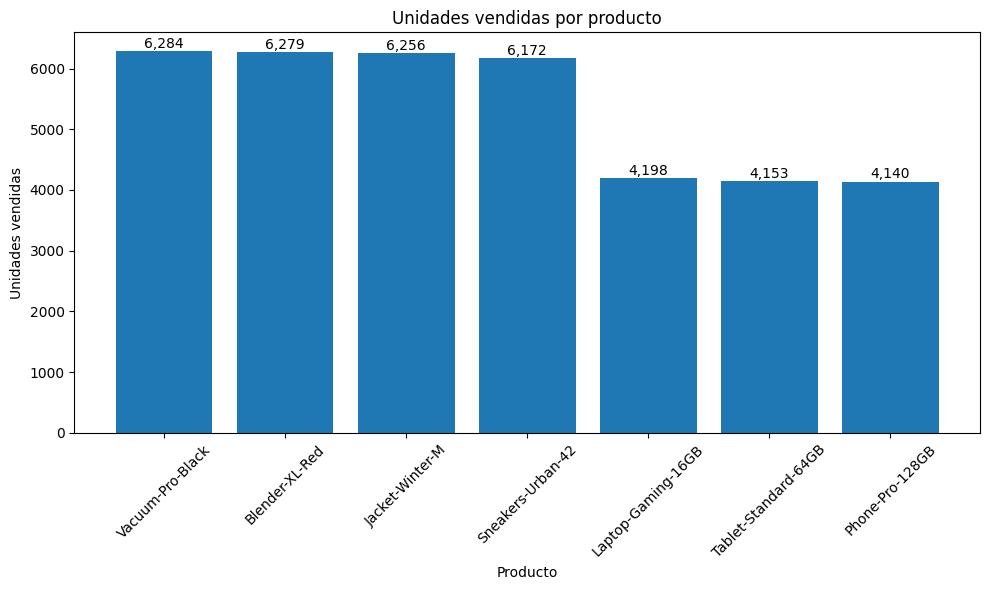

In [62]:
# Calcular unidades vendidas por producto
ventas_producto = (
    orders
    .groupby('nombre_producto')['cantidad']
    .sum()
    .sort_values(ascending=False)
)

# Graficar unidades vendidas por producto
plt.figure(figsize=(10, 6))

barras = plt.bar(
    ventas_producto.index,
    ventas_producto.values
)

# Agregar valores sobre las barras
for barra in barras:
    altura = barra.get_height()
    
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 50,
        f'{altura:,.0f}',
        ha='center'
    )

plt.title('Unidades vendidas por producto')
plt.xlabel('Producto')
plt.ylabel('Unidades vendidas')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

##### 📝 Producto más vendido

El producto con mayor volumen de ventas fue **`Vacuum-Pro-Black`**, con un total de **6,284 unidades vendidas** durante el periodo analizado.

Sin embargo, las ventas se encuentran relativamente próximas entre los productos con mayor volumen. Por ejemplo, `Blender-XL-Red` registró 6,279 unidades y `Jacket-Winter-M` 6,256 unidades.

Por lo tanto, aunque `Vacuum-Pro-Black` ocupa la primera posición en unidades vendidas, no se observa una diferencia amplia respecto a los siguientes productos.

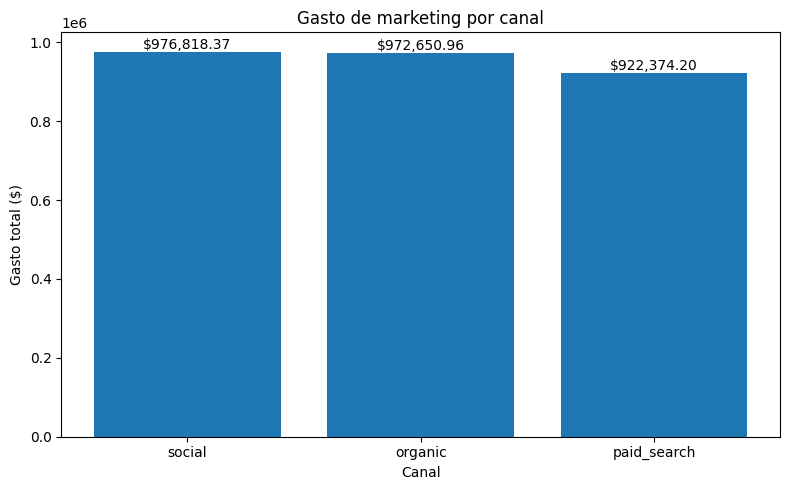

In [63]:
# Calcular el gasto total de marketing por canal
gasto_canal = (
    marketing
    .groupby('canal')['gasto']
    .sum()
    .sort_values(ascending=False)
)

# Graficar gasto de marketing por canal
plt.figure(figsize=(8, 5))

barras = plt.bar(
    gasto_canal.index,
    gasto_canal.values
)

# Agregar valores sobre las barras
for barra in barras:
    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        f'${altura:,.2f}',
        ha='center',
        va='bottom'
    )

plt.title('Gasto de marketing por canal')
plt.xlabel('Canal')
plt.ylabel('Gasto total ($)')

plt.tight_layout()
plt.show()

In [64]:
# Calcular participación de cada canal en la inversión total
participacion_canal = (
    gasto_canal / gasto_marketing * 100
).round(2)


##### 📝 Inversión en marketing por canal

La inversión en marketing se distribuyó de la siguiente manera:

- **Social:** \$976,818.37 (34.01 %)
- **Organic:** \$972,650.96 (33.87 %)
- **Paid search:** \$922,374.20 (32.12 %)

El canal `social` recibió la mayor inversión, con **\$976,818.37**, equivalente al **34.01 %** del gasto total en marketing. Sin embargo, la distribución del presupuesto fue relativamente equilibrada entre los tres canales, ya que cada uno concentró aproximadamente un tercio de la inversión.

Estos resultados describen la distribución del gasto, pero por sí solos no permiten determinar qué canal fue más rentable, ya que para ello sería necesario relacionar la inversión de cada canal con los ingresos o ganancias generados.

##### 📝 Conclusión del análisis de rentabilidad y comportamiento de ventas

Los resultados muestran que, considerando los costos disponibles en los datasets, **el negocio fue rentable durante el periodo analizado**. Para los pedidos con producto identificado se analizaron ingresos por **\$9,610,018.94**, frente a un costo de productos de **\$3,828,869.01** y una inversión en marketing de **\$2,871,843.53**. Después de considerar estos conceptos, se obtuvo una **ganancia de \$2,909,306.40**, equivalente a un **margen de ganancia del 30.27 %**.

En cuanto al comportamiento de las ventas, el **ticket promedio fue de \$385.88 por pedido**, con una cantidad promedio de **1.50 productos por orden**. El producto con mayor volumen de ventas fue **`Vacuum-Pro-Black`**, con **6,284 unidades**, aunque su volumen fue similar al de otros productos con alta demanda.

Por otra parte, la inversión en marketing se distribuyó de manera relativamente equilibrada entre los canales. `social` concentró la mayor proporción con **34.01 %**, seguido de `organic` con **33.87 %** y `paid_search` con **32.12 %**.

En conjunto, los indicadores permiten concluir que **el negocio genera una ganancia positiva bajo los costos considerados y presenta una distribución relativamente equilibrada de las ventas y de la inversión en marketing**. Sin embargo, para determinar qué productos, categorías o canales aportan mayor valor al negocio será necesario analizar su rentabilidad de manera segmentada.

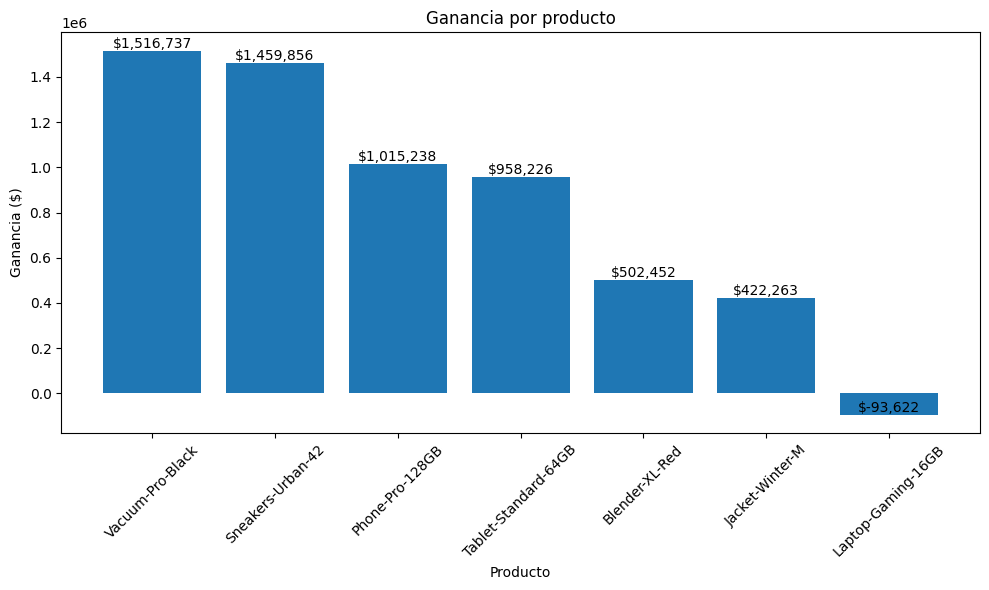

In [65]:
# Calcular costo y ganancia por pedido
rentabilidad['costo_total'] = (
    rentabilidad['cantidad'] * rentabilidad['costo_unitario']
)

rentabilidad['ganancia'] = (
    rentabilidad['monto_total'] - rentabilidad['costo_total']
)

# Ganancia por producto
ganancia_producto = (
    rentabilidad
    .groupby('nombre_producto')['ganancia']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

barras = plt.bar(
    ganancia_producto.index,
    ganancia_producto.values
)

for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        f'${altura:,.0f}',
        ha='center',
        va='bottom'
    )

plt.title('Ganancia por producto')
plt.xlabel('Producto')
plt.ylabel('Ganancia ($)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

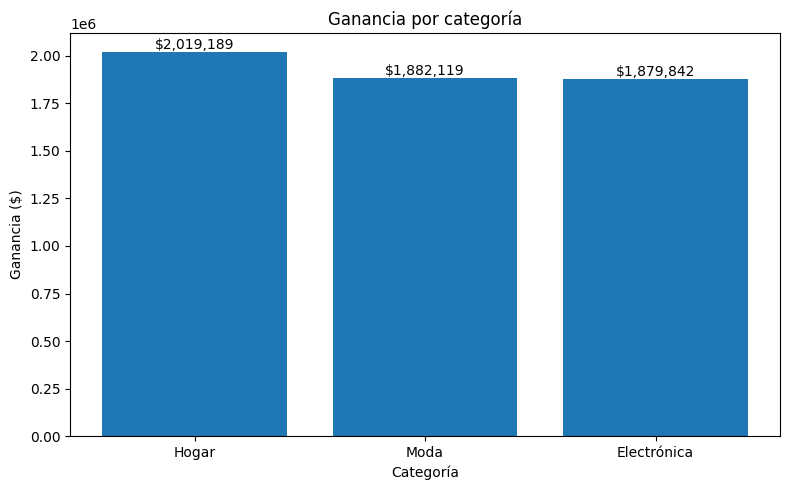

In [66]:
# Ganancia por categoría
ganancia_categoria = (
    rentabilidad
    .groupby('categoria_producto')['ganancia']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

barras = plt.bar(
    ganancia_categoria.index,
    ganancia_categoria.values
)

for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        f'${altura:,.0f}',
        ha='center',
        va='bottom'
    )

plt.title('Ganancia por categoría')
plt.xlabel('Categoría')
plt.ylabel('Ganancia ($)')

plt.tight_layout()
plt.show()

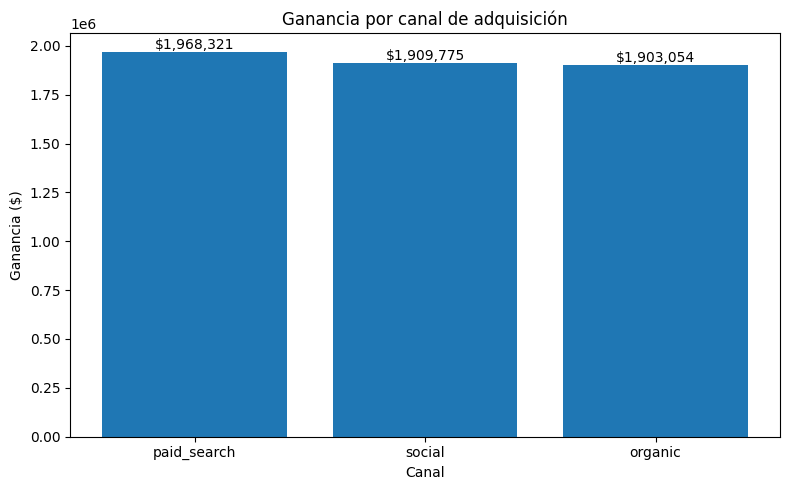

In [67]:
# Ganancia por canal
ganancia_canal = (
    rentabilidad
    .groupby('fuente_referencia')['ganancia']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

barras = plt.bar(
    ganancia_canal.index,
    ganancia_canal.values
)

for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        f'${altura:,.0f}',
        ha='center',
        va='bottom'
    )

plt.title('Ganancia por canal de adquisición')
plt.xlabel('Canal')
plt.ylabel('Ganancia ($)')

plt.tight_layout()
plt.show()

##### 🔎 Hallazgos de rentabilidad

**Contexto:**  
Se analizó la ganancia de manera segmentada por producto, categoría y canal de adquisición para determinar si la rentabilidad general del negocio se distribuye de manera uniforme.

**Hallazgo:**  
La rentabilidad presenta las mayores diferencias a nivel de producto. Mientras los productos con mayor contribución generan aproximadamente $1.52$ millones y $1.46$ millones, uno de los productos registra una pérdida cercana a $93.6$ mil.

Por categoría, `Hogar` presenta la mayor ganancia con aproximadamente $2.02$ millones, aunque `Moda` y `Electrónica` muestran valores cercanos. Asimismo, la ganancia por canal se encuentra relativamente equilibrada, con `paid_search` ligeramente por encima de `social` y `organic`.

**Implicación:**  
El principal punto de atención se encuentra a nivel de producto, ya que la rentabilidad no se distribuye uniformemente y existe un producto que reduce la ganancia global. Por ello, conviene revisar específicamente su relación entre costo, precio de venta y volumen vendido.

En el caso de los canales, la ganancia generada por sí sola no permite determinar cuál es más eficiente; para ello sería necesario relacionarla con la inversión de marketing correspondiente.

---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
# Configurar una conexión PostgreSQL autorizada mediante variables de entorno.
# La sección SQL requiere acceso a las tablas del proyecto.
import os
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

required = ["PGUSER", "PGPASSWORD", "PGHOST", "PGDATABASE"]
missing = [key for key in required if not os.getenv(key)]
if missing:
    raise EnvironmentError(f"Configura estas variables de entorno antes de ejecutar SQL: {', '.join(missing)}")

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.environ["PGUSER"],
    password=os.environ["PGPASSWORD"],
    host=os.environ["PGHOST"],
    port=int(os.getenv("PGPORT", "5432")),
    database=os.environ["PGDATABASE"],
)
engine = create_engine(connection_url, connect_args={"sslmode": "require"})


In [ ]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

In [ ]:
query_eventos = '''
SELECT
    nombre_evento,
    COUNT(*) AS total_eventos
FROM events
GROUP BY nombre_evento
ORDER BY total_eventos DESC;
'''

eventos = pd.read_sql(query_eventos, con=engine)
eventos

In [ ]:
# PARTE 1: Totales del funnel
# ============================


query_totals = '''
SELECT
    nombre_evento,
    COUNT(DISTINCT id_usuario) AS usuarios
FROM events
GROUP BY nombre_evento
ORDER BY CASE
    WHEN nombre_evento = 'first_visit' THEN 1
    WHEN nombre_evento = 'select_item' THEN 2
    WHEN nombre_evento = 'add_to_cart' THEN 3
    WHEN nombre_evento = 'begin_checkout' THEN 4
    WHEN nombre_evento = 'add_payment_info' THEN 5
    WHEN nombre_evento = 'purchase' THEN 6
    ELSE 7
END;
'''

totals = pd.read_sql(query_totals, con=engine)

totals

##### 📝 Revisión del primer cálculo del funnel

En una primera aproximación se calculó el número de usuarios únicos asociados a cada `nombre_evento` mediante `COUNT(DISTINCT id_usuario)`.

Sin embargo, los resultados muestran que `add_to_cart` registra **7,634 usuarios**, mientras que `select_item` registra **7,582 usuarios**. Esto implica que el número de usuarios aumenta entre dos etapas consecutivas, lo cual no es consistente con un funnel secuencial.

El problema se debe a que el conteo anterior considera de manera independiente a todos los usuarios que realizaron cada evento, sin verificar que hayan recorrido previamente las etapas anteriores.

Por lo tanto, para construir correctamente el funnel se debe considerar únicamente a los usuarios que avanzan de manera acumulativa a través de las etapas del proceso.

In [ ]:

# Ajustar el cálculo para construir un funnel acumulativo
query_totals = '''
WITH etapas_usuario AS (
    SELECT
        id_usuario,
        MAX(CASE WHEN nombre_evento = 'first_visit' THEN 1 ELSE 0 END) AS first_visit,
        MAX(CASE WHEN nombre_evento = 'select_item' THEN 1 ELSE 0 END) AS select_item,
        MAX(CASE WHEN nombre_evento = 'add_to_cart' THEN 1 ELSE 0 END) AS add_to_cart,
        MAX(CASE WHEN nombre_evento = 'begin_checkout' THEN 1 ELSE 0 END) AS begin_checkout,
        MAX(CASE WHEN nombre_evento = 'add_payment_info' THEN 1 ELSE 0 END) AS add_payment_info,
        MAX(CASE WHEN nombre_evento = 'purchase' THEN 1 ELSE 0 END) AS purchase
    FROM events
    GROUP BY id_usuario
)

SELECT
    'first_visit' AS nombre_evento,
    COUNT(*) FILTER (
        WHERE first_visit = 1
    ) AS usuarios
FROM etapas_usuario

UNION ALL

SELECT
    'select_item',
    COUNT(*) FILTER (
        WHERE first_visit = 1
          AND select_item = 1
    )
FROM etapas_usuario

UNION ALL

SELECT
    'add_to_cart',
    COUNT(*) FILTER (
        WHERE first_visit = 1
          AND select_item = 1
          AND add_to_cart = 1
    )
FROM etapas_usuario

UNION ALL

SELECT
    'begin_checkout',
    COUNT(*) FILTER (
        WHERE first_visit = 1
          AND select_item = 1
          AND add_to_cart = 1
          AND begin_checkout = 1
    )
FROM etapas_usuario

UNION ALL

SELECT
    'add_payment_info',
    COUNT(*) FILTER (
        WHERE first_visit = 1
          AND select_item = 1
          AND add_to_cart = 1
          AND begin_checkout = 1
          AND add_payment_info = 1
    )
FROM etapas_usuario

UNION ALL

SELECT
    'purchase',
    COUNT(*) FILTER (
        WHERE first_visit = 1
          AND select_item = 1
          AND add_to_cart = 1
          AND begin_checkout = 1
          AND add_payment_info = 1
          AND purchase = 1
    )
FROM etapas_usuario;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

##### 📝 Funnel acumulativo de usuarios

Después de ajustar la consulta para considerar únicamente a los usuarios que alcanzaron las etapas anteriores, se obtuvo un funnel acumulativo y decreciente.

El recorrido comienza con **7,796 usuarios** en `first_visit`. Posteriormente, **7,393** alcanzan `select_item`, **7,052** llegan a `add_to_cart`, **6,364** continúan a `begin_checkout`, **4,967** registran `add_payment_info` y finalmente **3,857 usuarios** alcanzan `purchase`.

A diferencia del primer conteo independiente por evento, este resultado permite observar de manera coherente la disminución progresiva de usuarios a medida que avanzan por las etapas del proceso.

In [ ]:
# PARTE 2: Conversiones
# =====================

query_conversion = '''
WITH etapas_usuario AS (
    SELECT
        id_usuario,
        MAX(CASE WHEN nombre_evento = 'first_visit' THEN 1 ELSE 0 END) AS first_visit,
        MAX(CASE WHEN nombre_evento = 'select_item' THEN 1 ELSE 0 END) AS select_item,
        MAX(CASE WHEN nombre_evento = 'add_to_cart' THEN 1 ELSE 0 END) AS add_to_cart,
        MAX(CASE WHEN nombre_evento = 'begin_checkout' THEN 1 ELSE 0 END) AS begin_checkout,
        MAX(CASE WHEN nombre_evento = 'add_payment_info' THEN 1 ELSE 0 END) AS add_payment_info,
        MAX(CASE WHEN nombre_evento = 'purchase' THEN 1 ELSE 0 END) AS purchase
    FROM events
    GROUP BY id_usuario
),

funnel AS (
    SELECT 1 AS orden, 'first_visit' AS nombre_evento,
           COUNT(*) FILTER (WHERE first_visit = 1) AS usuarios
    FROM etapas_usuario

    UNION ALL

    SELECT 2, 'select_item',
           COUNT(*) FILTER (
               WHERE first_visit = 1
                 AND select_item = 1
           )
    FROM etapas_usuario

    UNION ALL

    SELECT 3, 'add_to_cart',
           COUNT(*) FILTER (
               WHERE first_visit = 1
                 AND select_item = 1
                 AND add_to_cart = 1
           )
    FROM etapas_usuario

    UNION ALL

    SELECT 4, 'begin_checkout',
           COUNT(*) FILTER (
               WHERE first_visit = 1
                 AND select_item = 1
                 AND add_to_cart = 1
                 AND begin_checkout = 1
           )
    FROM etapas_usuario

    UNION ALL

    SELECT 5, 'add_payment_info',
           COUNT(*) FILTER (
               WHERE first_visit = 1
                 AND select_item = 1
                 AND add_to_cart = 1
                 AND begin_checkout = 1
                 AND add_payment_info = 1
           )
    FROM etapas_usuario

    UNION ALL

    SELECT 6, 'purchase',
           COUNT(*) FILTER (
               WHERE first_visit = 1
                 AND select_item = 1
                 AND add_to_cart = 1
                 AND begin_checkout = 1
                 AND add_payment_info = 1
                 AND purchase = 1
           )
    FROM etapas_usuario
),

conversiones AS (
    SELECT
        orden,
        nombre_evento,
        usuarios,
        LAG(usuarios) OVER (ORDER BY orden) AS usuarios_etapa_anterior
    FROM funnel
)

SELECT
    nombre_evento,
    usuarios,
    usuarios_etapa_anterior,
    usuarios_etapa_anterior - usuarios AS usuarios_perdidos,
    ROUND(
        usuarios * 100.0 / usuarios_etapa_anterior,
        2
    ) AS tasa_conversion
FROM conversiones
ORDER BY orden;
'''

conversion = pd.read_sql(query_conversion, con=engine)

conversion

##### 🔎 Hallazgos del funnel

**Contexto:**  
Se analizó el avance de los usuarios a través de las distintas etapas del funnel de compra, desde `first_visit` hasta `purchase`, considerando únicamente a quienes completaron de forma acumulativa las etapas anteriores.

**Hallazgo:**  
El funnel comienza con **7,796 usuarios** en `first_visit` y finaliza con **3,857 usuarios** en `purchase`. La mayor pérdida absoluta ocurre entre `begin_checkout` y `add_payment_info`, donde se pierden **1,397 usuarios** y la conversión entre ambas etapas es de **78.05 %**.

Además, la menor tasa de conversión entre etapas se presenta de `add_payment_info` a `purchase`, con **77.65 %**, lo que representa la pérdida de otros **1,110 usuarios**.

La conversión global desde `first_visit` hasta `purchase` fue de **49.47 %**, por lo que aproximadamente la mitad de los usuarios que ingresaron al funnel completaron finalmente una compra.

**Implicación:**  
Las principales oportunidades de mejora se concentran en las etapas finales del proceso de compra, particularmente desde el inicio del checkout hasta la finalización del pago. Esto sugiere revisar posibles puntos de fricción relacionados con el registro de la información de pago y la confirmación de la compra.

Para profundizar en el hallazgo, resulta conveniente segmentar estas tasas de conversión por variables como `dispositivo`, `pais` y `fuente_referencia`, con el objetivo de determinar si las pérdidas se concentran en grupos específicos de usuarios antes de proponer cambios en el proceso.

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

##### 📊 Construcción de las cohortes de retención

La exploración de las tablas muestra que los usuarios pueden agruparse según el **mes de registro**, mientras que `user_activity` registra su estado de actividad a los **7, 14, 21 y 28 días posteriores al registro**, correspondientes a las semanas 1, 2, 3 y 4.

Para cada cohorte se calculará el número inicial de usuarios y posteriormente se contabilizarán aquellos con `activo = 1` en cada semana. La retención semanal se calculará como la proporción de usuarios activos respecto al total de usuarios registrados originalmente en cada cohorte.

Cada semana se analizará de manera independiente, por lo que un usuario puede no estar activo en una semana y volver a estarlo en una semana posterior.

In [ ]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH usuarios_cohorte AS (
    SELECT
        id_usuario,
        DATE_TRUNC(
            'month',
            CAST(fecha_registro AS DATE)
        )::DATE AS cohorte
    FROM users
),

retencion AS (
    SELECT
        u.cohorte,
        COUNT(DISTINCT u.id_usuario) AS usuarios_cohorte,

        COUNT(DISTINCT CASE
            WHEN a.dias_despues_registro = 7
                 AND a.activo = 1
            THEN u.id_usuario
        END) AS retenido_w1,

        COUNT(DISTINCT CASE
            WHEN a.dias_despues_registro = 14
                 AND a.activo = 1
            THEN u.id_usuario
        END) AS retenido_w2,

        COUNT(DISTINCT CASE
            WHEN a.dias_despues_registro = 21
                 AND a.activo = 1
            THEN u.id_usuario
        END) AS retenido_w3,

        COUNT(DISTINCT CASE
            WHEN a.dias_despues_registro = 28
                 AND a.activo = 1
            THEN u.id_usuario
        END) AS retenido_w4

    FROM usuarios_cohorte AS u
    LEFT JOIN user_activity AS a
        ON u.id_usuario = a.id_usuario

    GROUP BY u.cohorte
)

SELECT
    cohorte,
    usuarios_cohorte,
    retenido_w1,
    retenido_w2,
    retenido_w3,
    retenido_w4,

    ROUND(
        retenido_w1 * 100.0 / usuarios_cohorte,
        2
    ) AS semana_1,

    ROUND(
        retenido_w2 * 100.0 / usuarios_cohorte,
        2
    ) AS semana_2,

    ROUND(
        retenido_w3 * 100.0 / usuarios_cohorte,
        2
    ) AS semana_3,

    ROUND(
        retenido_w4 * 100.0 / usuarios_cohorte,
        2
    ) AS semana_4

FROM retencion
ORDER BY cohorte;
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(
    query_cohort_retention_final,
    con=engine
)

cohorte_final

##### 📊 Análisis de retención por cohortes

La retención semanal se mantiene relativamente estable entre las cohortes analizadas, con valores cercanos al **40–44 %** durante las cuatro semanas posteriores al registro.

No se observa una tendencia general de disminución o crecimiento conforme avanzan las semanas. Algunas cohortes presentan ligeras recuperaciones después de una caída, mientras que otras muestran pequeñas variaciones entre periodos. La mayor retención observada corresponde a la cohorte de **febrero de 2025 en la semana 3, con 43.98 %**, mientras que la menor corresponde a esta misma cohorte en la **semana 4, con 39.82 %**.

Debido a que cada semana se calcula de manera independiente, un aumento de la retención entre periodos indica que algunos usuarios que no estuvieron activos en una semana pueden volver a estarlo posteriormente.

##### 💡 Hallazgo de retención

**Contexto:**  
Se comparó la retención de las cohortes registradas entre enero y mayo de 2025 durante las primeras cuatro semanas posteriores al registro, con el objetivo de determinar si los usuarios continúan utilizando la plataforma.

**Hallazgo:**  
La retención se mantiene relativamente estable entre las cohortes y semanas analizadas, oscilando entre **39.82 % y 43.98 %**. No se observa una caída progresiva conforme transcurren las semanas ni diferencias pronunciadas entre las cohortes. En términos generales, alrededor de **4 de cada 10 usuarios** se encuentran activos en cada periodo analizado.

**Implicación:**  
El principal punto de atención no parece ser una pérdida progresiva de usuarios conforme pasan las semanas, sino que desde la primera semana solamente alrededor del **40–43 %** vuelve a estar activo. Por ello, resulta conveniente analizar la retención por características como `tipo_plan`, `dispositivo` y `pais` para determinar si existen segmentos con comportamientos diferentes y orientar posibles estrategias de reactivación.


---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**  

### 🧪 Hipótesis estadística

El objetivo del experimento es determinar si la modificación de la interfaz de checkout produce un cambio estadísticamente significativo en la tasa de conversión.

- **H₀ (Hipótesis nula):** La tasa de conversión del grupo de tratamiento es igual a la tasa de conversión del grupo de control.

- **H₁ (Hipótesis alternativa):** La tasa de conversión del grupo de tratamiento es diferente de la tasa de conversión del grupo de control.

En términos estadísticos:

**H₀:** p_control = p_tratamiento

**H₁:** p_control ≠ p_tratamiento

**Test estadístico:** prueba Z para la diferencia entre dos proporciones independientes.

**Nivel de significancia:** α = 0.05.

In [77]:
import pandas as pd

# Cargar datos del experimento
url = 'https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv'

experiment = pd.read_csv(url)

experiment.head()


,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [78]:
# Revisar información general
experiment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


In [79]:
# Revisar valores ausentes
experiment.isna().sum()

id_usuario         0
variante           0
convirtio          0
dispositivo        0
pais               0
duracion_sesion    0
timestamp          0
dtype: int64

In [80]:
# Revisar registros duplicados y usuarios únicos
print("Filas duplicadas:", experiment.duplicated().sum())
print("Registros totales:", len(experiment))
print("Usuarios únicos:", experiment['id_usuario'].nunique())

Filas duplicadas: 0
Registros totales: 10000
Usuarios únicos: 10000


In [81]:
# Revisar variantes del experimento
experiment['variante'].value_counts()

tratamiento    5035
control        4965
Name: variante, dtype: int64

In [82]:
# Revisar valores de conversión
experiment['convirtio'].value_counts()

0    8401
1    1599
Name: convirtio, dtype: int64

In [83]:
# Verificar que ningún usuario pertenezca a más de una variante
usuarios_multivariante = (
    experiment
    .groupby('id_usuario')['variante']
    .nunique()
)

print(
    "Usuarios presentes en más de una variante:",
    (usuarios_multivariante > 1).sum()
)

Usuarios presentes en más de una variante: 0


In [84]:
# Calcular conversión por variante
conversion_variante = (
    experiment
    .groupby('variante')['convirtio']
    .agg(['count', 'sum', 'mean'])
)

conversion_variante['tasa_conversion'] = (
    conversion_variante['mean'] * 100
)

conversion_variante

,count,sum,mean,tasa_conversion
variante,,,,
control,4965,779,0.156898,15.689829
tratamiento,5035,820,0.162860,16.285998


In [85]:
# Aplicar prueba Z para dos proporciones
from statsmodels.stats.proportion import proportions_ztest

# Número de conversiones por grupo
conversiones_control = experiment.loc[
    experiment['variante'] == 'control',
    'convirtio'
].sum()

conversiones_tratamiento = experiment.loc[
    experiment['variante'] == 'tratamiento',
    'convirtio'
].sum()

# Número de usuarios por grupo
n_control = (
    experiment['variante'] == 'control'
).sum()

n_tratamiento = (
    experiment['variante'] == 'tratamiento'
).sum()

# Conversiones y tamaños de muestra
conversiones = [
    conversiones_control,
    conversiones_tratamiento
]

usuarios = [
    n_control,
    n_tratamiento
]

# Prueba Z bilateral
z_stat, p_value = proportions_ztest(
    conversiones,
    usuarios,
    alternative='two-sided'
)

print(f"Estadístico Z: {z_stat:.4f}")
print(f"Valor p: {p_value:.4f}")

Estadístico Z: -0.8133
Valor p: 0.4161


##### 💡 Hallazgo del experimento

**Contexto:**  
Se comparó la tasa de conversión entre las variantes de control y tratamiento para determinar si la modificación de la interfaz de checkout produjo un cambio estadísticamente significativo.

**Hallazgo:**  
La conversión fue de **15.69 %** en control y **16.29 %** en tratamiento, una diferencia observada de **0.60 puntos porcentuales**. Sin embargo, la prueba Z obtuvo **p = 0.4161**, superior a α = 0.05, por lo que no se rechaza la hipótesis nula.

**Implicación:**  
La evidencia disponible no permite atribuir el incremento observado al cambio de interfaz. Por ello, no se justifica implementar la nueva versión únicamente bajo el argumento de que aumenta la conversión. Si el cambio continúa siendo relevante para el negocio, sería conveniente definir un efecto mínimo de interés y calcular el tamaño de muestra requerido para una nueva evaluación.


---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

---

### Dashboard de Power BI

[Consultar la carpeta compartida del dashboard](https://drive.google.com/drive/folders/1SpqCyTmx1JBHOuOXvLxj40zd3_TVsKKu?usp=sharing)

*La disponibilidad y los permisos del enlace dependen de su propietario.*
